# 01: Whisper evaluation on MIT lectures (audio + PDF transcript)

**Goal:** measure transcription accuracy (word error rate, WER) and speed for each Whisper size, on GPU and on CPU (your deployed app runs on CPU). It also produces a 15-minute timestamped transcript per lecture for notebook 02.

**What is automatic:**
- It cuts short audio clips (default: two 3-minute clips per lecture, at minute 10 and minute 25).
- MIT OCW transcript PDFs have **no timestamps**, so the notebook finds where each clip sits in the PDF text by alignment (see below). You do not have to cut the PDF by hand.
- It cleans the PDF text (speaker labels such as `PROFESSOR:`, tags such as `[SQUEAKING]`, page numbers).

**Put these in Google Drive:**
```
MyDrive/lecture_eval/
  audio/lecture1.mp3     (or .mp4 / .wav / .m4a; the full ~40 min lecture)
  audio/lecture2.mp3
  audio/lecture3.mp3
  pdf/lecture1.pdf       (the matching OCW transcript PDF)
  pdf/lecture2.pdf
  pdf/lecture3.pdf
```
Use **Runtime > Change runtime type > T4 GPU**.

**How the PDF is matched (explain this in your viva):** Whisper transcribes the clip; then an "ends-free" edit-distance alignment slides that text along the whole PDF transcript and finds the stretch of PDF text with the fewest differences. That stretch becomes the reference for that clip. The *largest* model's output is used only to **locate** the stretch, and then **every** model is scored against that same fixed reference text, so the comparison is fair.

In [1]:
!pip -q install faster-whisper jiwer pypdf whisper-normalizer nvidia-cublas-cu12 "nvidia-cudnn-cu12>=9,<10"
import torch
print("GPU available (torch):", torch.cuda.is_available())

GPU available (torch): True


In [2]:
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/lecture_eval"
LECTURES = ["lecture1", "lecture2", "lecture3"]   # file names without extension

CLIP_SECONDS = 180            # length of each evaluation clip
CLIP_STARTS = [600, 1500]     # seconds into the lecture (minute 10 and 25); skipped if the file is too short
EXCERPT_START = 600           # the 15-minute excerpt used for summaries/quizzes in notebook 02
EXCERPT_MINUTES = 15          # matches the app's 15-minute upload limit

GPU_MODELS = ["tiny", "base", "small"]
CPU_MODELS = ["tiny", "base"]   # deployment is CPU, so measure CPU speed too (add "small" if you have time)
BEST_MODEL = "base"             # set this after you have seen the results below

Mounted at /content/drive


In [3]:
import os, glob, json, re, subprocess

for d in ["clips", "excerpts", "refs", "out/whisper_hyp", "out/transcripts"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)

def find_audio(name):
    files = glob.glob(f"{ROOT}/audio/{name}.*")
    assert files, f"No audio found for {name} in {ROOT}/audio"
    return files[0]

def to_wav(src, dst, seconds=None, start=0):
    """16 kHz mono WAV, same format as backend/audio.py."""
    cmd = ["ffmpeg", "-y"]
    if start:
        cmd += ["-ss", str(start)]
    cmd += ["-i", src]
    if seconds:
        cmd += ["-t", str(seconds)]
    cmd += ["-vn", "-ac", "1", "-ar", "16000", dst]
    subprocess.run(cmd, capture_output=True, check=True)

def duration(path):
    out = subprocess.run(
        ["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "json", path],
        capture_output=True, text=True, check=True)
    return float(json.loads(out.stdout)["format"]["duration"])

## Load and clean the PDF transcripts
Check the printed previews. If a preview shows junk (headers, strange symbols), adjust `clean_transcript`. If the PDF is a scanned image, no words will be extracted and the cell will stop with an error (you would need OCR or a different transcript source).

In [4]:
from pypdf import PdfReader

try:
    from whisper_normalizer.english import EnglishTextNormalizer
    _en_norm = EnglishTextNormalizer()
    def normalise(t):
        return _en_norm(t)          # lower-cases, strips punctuation, "twenty one" -> "21", UK/US spelling
    print("Using Whisper's English text normaliser")
except Exception:
    def normalise(t):
        t = re.sub(r"\[[^\]]*\]", " ", t.lower())
        t = re.sub(r"[^\w\s']", " ", t)
        return re.sub(r"\s+", " ", t).strip()
    print("Whisper normaliser not available; using basic normalisation")

def basic_word(tok):
    return re.sub(r"[^\w']", "", tok.lower())

def clean_transcript(raw):
    t = raw.replace("\r", "")
    t = re.sub(r"(?m)^\s*MITOCW.*$", " ", t)                                   # MITOCW | watch?v=... header
    t = re.sub(r"The following content is provided under.*?ocw\.mit\.edu\.?", " ", t, flags=re.S)  # licence blurb
    t = re.sub(r"-\n(?=[a-z])", "", t)                      # words hyphenated across lines
    t = re.sub(r"\[[^\]]*\]", " ", t)                       # [SQUEAKING], [RUSTLING], [CLICKING] ...
    t = re.sub(r"(?m)^\s*(PROFESSOR|SPEAKER\s*\d*|STUDENT|AUDIENCE|[A-Z][A-Z. ]{2,25}):\s*", "", t)  # speaker labels
    t = re.sub(r"(?m)^\s*\d+\s*$", "", t)                   # lone page numbers
    t = re.sub(r"(?mi)^\s*(https?://\S+|ocw\.mit\.edu.*|mit opencourseware.*)\s*$", "", t)  # header/footer lines
    return re.sub(r"[ \t]+", " ", t)

ref_clean, ref_words = {}, {}
for n in LECTURES:
    files = glob.glob(f"{ROOT}/pdf/{n}.pdf")
    assert files, f"No PDF found for {n} in {ROOT}/pdf"
    raw = "\n".join((p.extract_text() or "") for p in PdfReader(files[0]).pages)
    clean = clean_transcript(raw)
    words = normalise(clean).split()
    assert len(words) > 500, f"Only {len(words)} words extracted from {n}.pdf. Is it a scanned PDF?"
    ref_clean[n], ref_words[n] = clean, words
    print(f"{n}: {len(words)} words | preview: {clean[:250]!r}")

Using Whisper's English text normaliser
lecture1: 5095 words | preview: "All right, welcome to the 60002, or if you were in 600, the second half of 600. I'm John Guttag.\nLet me start with a few administrative things.\nWhat's the workload? There are problem sets. They'll all be programming problems much in\nthe style of 6000"
lecture2: 6046 words | preview: "We ended the last lecture looking at greedy algorithms. Today I want to discuss the pros and\ncons of greedy. Oh, I should mention-- in response to popular demand, I have put the\nPowerPoint up, so if you download the ZIP file, you'll find the question"
lecture3: 9730 words | preview: "Welcome back. Over the last couple of lectures, we've been looking at optimization models.\nAnd the idea was how do I find a way to optimize an objective function-- it could be minimize it\nor maximize it-- relative to a set of constraints? And we saw,"


## Cut the audio clips (automatic)
Clips start at the times in `CLIP_STARTS`. If a file is shorter than needed, a clip from the middle is used instead.

In [5]:
def clip_starts(name):
    total = duration(find_audio(name))
    ok = [s for s in CLIP_STARTS if s + CLIP_SECONDS <= total]
    return ok or [max(0, int(total / 2 - CLIP_SECONDS / 2))]

clips = []   # (lecture, start_sec, wav_path, clip_duration)
for n in LECTURES:
    for s in clip_starts(n):
        wav = f"{ROOT}/clips/{n}_{s}.wav"
        to_wav(find_audio(n), wav, CLIP_SECONDS, s)
        clips.append((n, s, wav, duration(wav)))
        print(f"{n}: clip at {s // 60}:{s % 60:02d}, {clips[-1][3]:.0f}s")

lecture1: clip at 10:00, 180s
lecture1: clip at 25:00, 180s
lecture2: clip at 10:00, 180s
lecture2: clip at 25:00, 180s
lecture3: clip at 10:00, 180s
lecture3: clip at 25:00, 180s


## GPU setup for faster-whisper
Colab's current image does not expose the CUDA 12 libraries (`libcublas.so.12`, cuDNN 9) that faster-whisper needs, so this cell loads them from the pip packages and then **tests** the GPU with a tiny model. If the GPU still does not work, `GPU_OK` becomes `False` and the notebook carries on with CPU models only (GPU rows are then simply missing from the results; say so in your report).

In [6]:
import ctypes, glob, importlib, os
import numpy as np

def preload_cuda12():
    """Load the pip-installed CUDA 12 libraries into this process so faster-whisper/ctranslate2 can find them."""
    loaded = []
    for pkg, names in [("nvidia.cublas.lib", ["libcublasLt.so.12", "libcublas.so.12"]),
                       ("nvidia.cudnn.lib", None)]:
        try:
            mod = importlib.import_module(pkg)
        except ImportError:
            continue
        d = os.path.dirname(mod.__file__) if getattr(mod, "__file__", None) else list(mod.__path__)[0]
        files = [os.path.join(d, n) for n in names] if names else sorted(glob.glob(os.path.join(d, "libcudnn*.so.9")))
        for _ in range(2):                       # two passes: some cuDNN libs depend on each other
            for f in files:
                try:
                    if os.path.exists(f):
                        ctypes.CDLL(f, mode=ctypes.RTLD_GLOBAL)
                        loaded.append(os.path.basename(f))
                except OSError:
                    pass
    return sorted(set(loaded))

print("Preloaded:", preload_cuda12())

from faster_whisper import WhisperModel

def gpu_works():
    try:
        m = WhisperModel("tiny", device="cuda", compute_type="float16")
        list(m.transcribe(np.zeros(16000 * 2, dtype="float32"), language="en")[0])
        return True
    except Exception as e:
        print("GPU is NOT usable for faster-whisper:", str(e)[:200])
        return False

GPU_OK = torch.cuda.is_available() and gpu_works()
print("GPU_OK =", GPU_OK)

Preloaded: ['libcublas.so.12', 'libcublasLt.so.12', 'libcudnn.so.9', 'libcudnn_adv.so.9', 'libcudnn_cnn.so.9', 'libcudnn_engines_precompiled.so.9', 'libcudnn_engines_runtime_compiled.so.9', 'libcudnn_engines_tensor_ir.so.9', 'libcudnn_ext.so.9', 'libcudnn_graph.so.9', 'libcudnn_heuristic.so.9', 'libcudnn_ops.so.9']


GPU_OK = True


## Step 1: transcribe every clip with every model (timed)
RTF (real-time factor) = processing time / audio length; below 1 means faster than real time.

In [7]:
import time, wave

SIZE_ORDER = ["tiny", "base", "small", "medium", "large-v3"]

def load_wav(path):
    """Read our 16 kHz mono WAV directly (avoids PyAV, which caused version errors)."""
    with wave.open(path, "rb") as w:
        assert w.getframerate() == 16000 and w.getnchannels() == 1, "expected 16 kHz mono WAV"
        raw = w.readframes(w.getnframes())
    return np.frombuffer(raw, dtype=np.int16).astype(np.float32) / 32768.0

def transcribe(model, audio):
    if isinstance(audio, str):
        audio = load_wav(audio)
    segments, info = model.transcribe(audio, beam_size=5, vad_filter=True, language="en")
    return [(s.start, s.end, s.text.strip()) for s in segments]   # consuming the generator = the actual work

configs = [("cuda", "float16", m) for m in GPU_MODELS if GPU_OK]
configs += [("cpu", "int8", m) for m in CPU_MODELS]
print("Running configurations:", configs)

hyps, timing = {}, {}
for device, ctype, mname in configs:
    model = WhisperModel(mname, device=device, compute_type=ctype)
    transcribe(model, np.zeros(16000, dtype="float32"))          # warm-up so load time is not counted
    for n, s, wav, dur in clips:
        audio = load_wav(wav)
        t0 = time.time()
        segs = transcribe(model, audio)
        proc = time.time() - t0
        hyp = " ".join(x[2] for x in segs)
        hyps[(device, mname, n, s)] = hyp
        timing[(device, mname, n, s)] = (dur, proc)
        open(f"{ROOT}/out/whisper_hyp/{device}_{mname}_{n}_{s}.txt", "w").write(hyp)
        print(device, mname, n, s, "RTF", round(proc / dur, 2))
    del model

Running configurations: [('cuda', 'float16', 'tiny'), ('cuda', 'float16', 'base'), ('cuda', 'float16', 'small'), ('cpu', 'int8', 'tiny'), ('cpu', 'int8', 'base')]
cuda tiny lecture1 600 RTF 0.02
cuda tiny lecture1 1500 RTF 0.01
cuda tiny lecture2 600 RTF 0.01
cuda tiny lecture2 1500 RTF 0.02
cuda tiny lecture3 600 RTF 0.02
cuda tiny lecture3 1500 RTF 0.02
cuda base lecture1 600 RTF 0.02
cuda base lecture1 1500 RTF 0.01
cuda base lecture2 600 RTF 0.02
cuda base lecture2 1500 RTF 0.02
cuda base lecture3 600 RTF 0.03
cuda base lecture3 1500 RTF 0.02
cuda small lecture1 600 RTF 0.03
cuda small lecture1 1500 RTF 0.02
cuda small lecture2 600 RTF 0.03
cuda small lecture2 1500 RTF 0.03
cuda small lecture3 600 RTF 0.04
cuda small lecture3 1500 RTF 0.04
cpu tiny lecture1 600 RTF 0.07
cpu tiny lecture1 1500 RTF 0.04
cpu tiny lecture2 600 RTF 0.07
cpu tiny lecture2 1500 RTF 0.06
cpu tiny lecture3 600 RTF 0.09
cpu tiny lecture3 1500 RTF 0.08
cpu base lecture1 600 RTF 0.14
cpu base lecture1 1500 RTF

## Step 2: find each clip in the PDF, then score
`locate` is an ends-free edit-distance alignment: the reference may have any number of unmatched words before and after the clip at no cost. It returns the best-matching stretch of the PDF. A length ratio near 1 and a low anchor error mean the match is right; the cell prints a warning otherwise.

In [8]:
def locate(ref_w, hyp_w):
    """Find the stretch of ref_w that best matches hyp_w. Returns (start, end, edit_cost)."""
    N, M = len(ref_w), len(hyp_w)
    ids = {}
    r = [ids.setdefault(w, len(ids)) for w in ref_w]
    h = [ids.setdefault(w, len(ids)) for w in hyp_w]
    prev_cost, prev_start = [0] * (N + 1), list(range(N + 1))      # free start anywhere in the reference
    for i in range(1, M + 1):
        hi = h[i - 1]
        cur_cost, cur_start = [i] + [0] * N, [0] * (N + 1)
        for j in range(1, N + 1):
            diag = prev_cost[j - 1] + (hi != r[j - 1])              # match / substitution
            ins = prev_cost[j] + 1                                  # extra word in the hypothesis
            dele = cur_cost[j - 1] + 1                              # reference word missing from the hypothesis
            if diag <= ins and diag <= dele:
                cur_cost[j], cur_start[j] = diag, prev_start[j - 1]
            elif ins <= dele:
                cur_cost[j], cur_start[j] = ins, prev_start[j]
            else:
                cur_cost[j], cur_start[j] = dele, cur_start[j - 1]
        prev_cost, prev_start = cur_cost, cur_start
    end = min(range(N + 1), key=prev_cost.__getitem__)              # free end anywhere in the reference
    return prev_start[end], end, prev_cost[end]

In [9]:
import jiwer
import pandas as pd

anchor = max(configs, key=lambda c: (SIZE_ORDER.index(c[2]), c[0] == "cuda"))
print("Largest model, used only to LOCATE each clip in the PDF:", anchor, "\n")

spans = {}
for n, s, wav, dur in clips:
    hw = normalise(hyps[(anchor[0], anchor[2], n, s)]).split()
    assert hw, f"Empty transcript for {n} @ {s}s (silent clip?)"
    a, b, cost = locate(ref_words[n], hw)
    ratio = (b - a) / len(hw)
    spans[(n, s)] = " ".join(ref_words[n][a:b])
    ok = 0.7 <= ratio <= 1.4 and cost / len(hw) < 0.5
    print(f"{n} @{s}s: PDF words {a}-{b} | anchor error {cost / len(hw):.2f} | length ratio {ratio:.2f}" +
          ("" if ok else "   <-- CHECK: this PDF may not match this audio"))

rows = []
for (device, mname, n, s), hyp in hyps.items():
    dur, proc = timing[(device, mname, n, s)]
    ref, h = spans[(n, s)], normalise(hyp)
    if h:
        o = jiwer.process_words(ref, h)
        wer, subs, dels, ins = o.wer, o.substitutions, o.deletions, o.insertions
    else:
        wer, subs, dels, ins = 1.0, 0, len(ref.split()), 0
    rows.append(dict(device=device, model=mname, lecture=n, clip_start=s, audio_sec=round(dur, 1),
                     proc_sec=round(proc, 1), rtf=round(proc / dur, 3), wer=round(wer, 4),
                     subs=subs, dels=dels, ins=ins))

df = pd.DataFrame(rows)
df.to_csv(f"{ROOT}/out/whisper_results.csv", index=False)
summary = (df.groupby(["device", "model"])
             .agg(WER=("wer", "mean"), RTF=("rtf", "mean"), proc_sec=("proc_sec", "mean"),
                  subs=("subs", "sum"), dels=("dels", "sum"), ins=("ins", "sum"))
             .round(3))
summary

Largest model, used only to LOCATE each clip in the PDF: ('cuda', 'float16', 'small') 

lecture1 @600s: PDF words 1316-1772 | anchor error 0.02 | length ratio 0.99
lecture1 @1500s: PDF words 3335-3638 | anchor error 0.03 | length ratio 1.01
lecture2 @600s: PDF words 1411-1807 | anchor error 0.11 | length ratio 0.93
lecture2 @1500s: PDF words 3315-3661 | anchor error 0.04 | length ratio 0.98
lecture3 @600s: PDF words 1771-2383 | anchor error 0.02 | length ratio 1.00
lecture3 @1500s: PDF words 4755-5350 | anchor error 0.02 | length ratio 1.00


WER    RTF  proc_sec  subs  dels  ins
device model                                         
cpu    base   0.054  0.146    26.317    70    16   53
       tiny   0.080  0.068    12.300   103    29   70
cuda   base   0.051  0.021     3.817    63    19   53
       small  0.042  0.030     5.450    47    10   48
       tiny   0.079  0.017     3.150   112    31   60

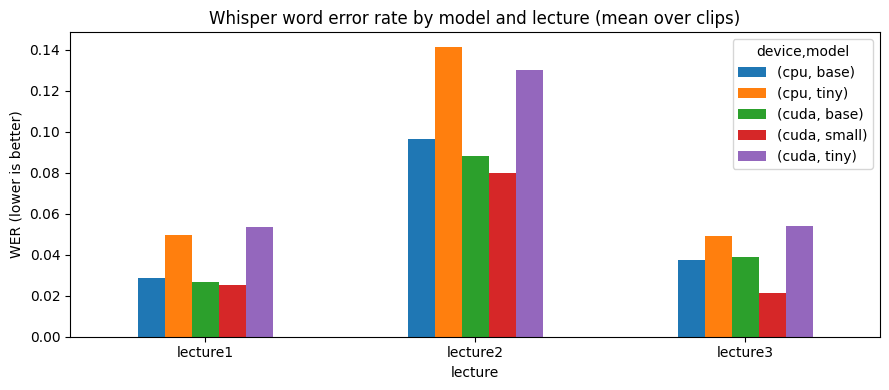

In [10]:
import matplotlib.pyplot as plt

piv = df.pivot_table(index="lecture", columns=["device", "model"], values="wer")
ax = piv.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("WER (lower is better)")
ax.set_title("Whisper word error rate by model and lecture (mean over clips)")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(f"{ROOT}/out/whisper_wer.png", dpi=150)
plt.show()

In [11]:
# Real errors for your report's error analysis: first clip, smallest CPU model
n, s, _, _ = clips[0]
key = ("cpu", CPU_MODELS[0], n, s)
o = jiwer.process_words(spans[(n, s)], normalise(hyps[key]))
print(jiwer.visualize_alignment(o)[:2500])

=== SENTENCE 1 ===

REF: the continuous or so called fractional *** knapsack problem says i can take pieces of it so maybe if i take in my gold bar and shaved it into gold dust i then can say well the whole thing will not fit in but i can fit in a path part of it the continuous *** knapsack problem is really boring it is easy to solve how do you think you would solve the continuous problem suppose you had over here a pile of gold and a pile of silver and a pile of raisins and you wanted to maximize your value well you would fill up your *** knapsack with gold until you either ran out of gold or ran out of space if you have not run out of space you will now put silver in until you run out of space if you still have not run out of space well then you will take as many raisins as you can fit in but you can solve it with what is called a greedy algorithm and we will talk much more about this as we go forward where you take the best thing 1st as long as you can and then you move on to the n

## Step 3: transcript excerpt for notebook 02
Pick `BEST_MODEL` in the config cell from the table above (the cheapest model whose WER is acceptable and whose CPU RTF is comfortably under 1), then run this cell. For each lecture it:
- transcribes a 15-minute excerpt into `[HH:MM:SS] text` lines (about 30 s per line, with times relative to the **whole lecture**) in `out/transcripts/`;
- finds the matching text in the PDF and saves it to `refs/lectureN_excerpt_reference.txt`, so you can **write your reference summary** from the correct 15 minutes without hunting through the PDF.

The alignment over 15 minutes takes about 20-60 seconds per lecture.

In [12]:
def fmt(t):
    return f"{int(t // 3600):02d}:{int(t % 3600 // 60):02d}:{int(t % 60):02d}"

def group(segs, window=30.0):
    lines, start, buf = [], None, []
    for s, e, text in segs:
        if start is None:
            start = s
        buf.append(text)
        if e - start >= window:
            lines.append(f"[{fmt(start)}] {' '.join(buf)}")
            start, buf = None, []
    if buf:
        lines.append(f"[{fmt(start)}] {' '.join(buf)}")
    return lines

def readable_tokens(clean):
    """(normalised word, original word) pairs, to save PDF text that is still readable."""
    txt = re.sub(r"(?<=\w)-(?=\w)", " ", clean)
    pairs = [(basic_word(t), t) for t in txt.split()]
    return [p for p in pairs if p[0]]

use_gpu = GPU_OK
model = WhisperModel(BEST_MODEL, device="cuda" if use_gpu else "cpu",
                     compute_type="float16" if use_gpu else "int8")

for n in LECTURES:
    total = duration(find_audio(n))
    start = int(min(EXCERPT_START, max(0, total - EXCERPT_MINUTES * 60)))
    wav = f"{ROOT}/excerpts/{n}_{start}.wav"
    to_wav(find_audio(n), wav, EXCERPT_MINUTES * 60, start)
    segs = [(s + start, e + start, t) for s, e, t in transcribe(model, wav)]   # absolute lecture time
    lines = group(segs)
    open(f"{ROOT}/out/transcripts/{n}.txt", "w").write("\n".join(lines))

    toks = readable_tokens(ref_clean[n])
    hw = [w for w in (basic_word(x) for x in " ".join(t for _, _, t in segs).replace("-", " ").split()) if w]
    a, b, cost = locate([t[0] for t in toks], hw)
    open(f"{ROOT}/refs/{n}_excerpt_reference.txt", "w").write(" ".join(t[1] for t in toks[a:b]))
    print(f"{n}: excerpt from {fmt(start)}, {len(lines)} lines, matched {b - a} PDF words (error {cost / len(hw):.2f})")

print(open(f"{ROOT}/out/transcripts/{LECTURES[0]}.txt").read()[:600])

lecture1: excerpt from 00:10:00, 27 lines, matched 1936 PDF words (error 0.04)
lecture2: excerpt from 00:10:00, 28 lines, matched 1813 PDF words (error 0.10)
lecture3: excerpt from 00:10:00, 29 lines, matched 2855 PDF words (error 0.03)
[00:10:01] The continuous or so-called fractional knapsack problem says I can take pieces of it So maybe if I take in my gold bar and shaved it into gold dust I then can say well the whole thing won't fit in but I can fit in a path part of it The continuous knapsack problem is really boring It's easy to solve How do you think you would solve a continuous problem? Suppose you had over here a pile of gold and a pile of silver and a pile of raisins
[00:10:37] And you wanted to maximize your value Well, you'd fill up your knapsack with gold until you either ran out of gold or ran out of space If y


## What to report
- Table of mean WER and RTF per device/model (the `summary` output), the chart, and how many clips and minutes of audio you evaluated (3 lectures x 2 clips x 3 min by default).
- The reference method: PDF transcripts, cleaned, aligned to each clip by ends-free edit distance, with one fixed reference per clip for all models. State that the PDF is a human-made transcript but not word-for-word (it may omit false starts or fillers), so some of the measured WER is reference noise, not Whisper error.
- Which model you chose for deployment and why (accuracy vs CPU speed).
- 2-3 concrete error examples (technical terms, names and equations are where Whisper usually fails) and what that means for the summaries.
- Limits: few clips, lectures from one source, one speaker style; results are indicative, not definitive.